In [1]:
import pandas as pd
import numpy as py
import os
import glob
import matplotlib.pyplot as plt


data_path = "./data/"

csv_files = glob.glob(data_path + "*.csv")

dataframe = {}

for file in csv_files:
    name = os.path.basename(file).replace(".csv","")
    dataframe[name] = pd.read_csv(file)

In [2]:
#统计支付总数
payments = dataframe["olist_order_payments_dataset"]

print("支付表行列数：",payments.shape)
payments.head()

支付表行列数： (103886, 5)


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [19]:
#统计不同支付方式的记录数量
payment_type_count = payments["payment_type"].value_counts()

print(payment_type_count)

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64


In [4]:
#统计每种支付方式涉及的订单数
payment_order_count = payments.groupby(
    "payment_type"
)["order_id"].nunique()
payment_order_count

payment_type
boleto         19784
credit_card    76505
debit_card      1528
not_defined        3
voucher         3866
Name: order_id, dtype: int64

In [5]:
#统计各支付方式的支付总金额
payment_amount = payments.groupby(
    "payment_type"
)["payment_value"].sum()
payment_amount = payment_amount.sort_values(
    ascending = False
)
payment_amount

payment_type
credit_card    12542084.19
boleto          2869361.27
voucher          379436.87
debit_card       217989.79
not_defined           0.00
Name: payment_value, dtype: float64

In [6]:
#平均金额
payment_avg = payments.groupby(
    "payment_type"
)["payment_value"].mean()

payment_avg = payment_avg.sort_values(
    ascending = False
)
payment_avg

payment_type
credit_card    163.319021
boleto         145.034435
debit_card     142.570170
voucher         65.703354
not_defined      0.000000
Name: payment_value, dtype: float64

In [7]:
#分析分期付款情况
installment_count = payments["payment_installments"].value_counts().sort_index()
print(installment_count)
#分期数频率

payment_installments
0         2
1     52546
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
11       23
12      133
13       16
14       15
15       74
16        5
17        8
18       27
20       17
21        3
22        1
23        1
24       18
Name: count, dtype: int64


In [8]:
print("一次性付清",
      ( payments["payment_installments"] == 1).sum())
print("分期记录数",
      (payments["payment_installments"] > 1).sum()
)
print("0期支付记录",
      (payments["payment_installments"] == 0).sum())
print((payments["payment_installments"]>1).sum() / len(payments) *100,"%")

一次性付清 52546
分期记录数 51338
0期支付记录 2
49.41763086460158 %


In [9]:
#一次付清略高于分期付款记录数，分期支付占约49%说明分期付款也是一个常见的付款方式,存在0次付款

In [10]:
#检查0期记录
zero_installments = payments[
    payments["payment_installments"] == 0
]
print(zero_installments)

                               order_id  payment_sequential payment_type  \
46982  744bade1fcf9ff3f31d860ace076d422                   2  credit_card   
79014  1a57108394169c0b47d8f876acc9ba2d                   2  credit_card   

       payment_installments  payment_value  
46982                     0          58.69  
79014                     0         129.94  


In [11]:
#统计各支付方式占比
payment_amount_rate = (
    payment_amount / payment_amount.sum() *100
)
payment_amount_rate = payment_amount_rate.sort_values(
    ascending = False
)
payment_amount_rate

payment_type
credit_card    78.344584
boleto         17.923569
voucher         2.370166
debit_card      1.361681
not_defined     0.000000
Name: payment_value, dtype: float64

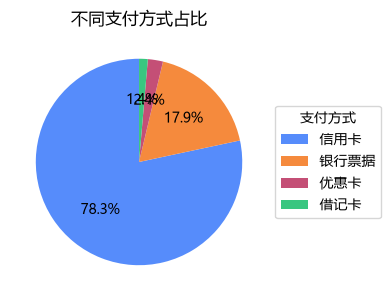

In [12]:
#图像分析
payment_amount_map = {
    "credit_card":"信用卡",
    "boleto":"银行票据",
    "voucher":"优惠卡",
    "debit_card":"借记卡"
}
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
payment_polt = payment_amount_rate[
    payment_amount_rate>0
].rename(index=payment_amount_map)
payment_polt.plot(
    kind="pie",
    autopct = "%1.1f%%",
    figsize = (4,4),
    startangle = 90,
   labels = None
)
plt.title("不同支付方式占比")
plt.legend(
    payment_polt.index,
    title = "支付方式",
    loc = "center left",
    bbox_to_anchor = (1,0.5),
)
plt.tight_layout()
plt.show()

In [13]:
#信用卡分期期数分布
credit_card = payments[
    payments["payment_type"]=="credit_card"
]
#统计不同分期期数
credit_installment_count = credit_card[
    "payment_installments"
].value_counts().sort_index()
credit_installment_count

payment_installments
0         2
1     25455
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
11       23
12      133
13       16
14       15
15       74
16        5
17        8
18       27
20       17
21        3
22        1
23        1
24       18
Name: count, dtype: int64

In [16]:
#统计信用卡一次性支付率和分期支付率
credit_one = (
    credit_card["payment_installments"] == 1
).sum()
credit_installment = (
    credit_card["payment_installments"] > 1
).sum()
credit_valid = (
    credit_card["payment_installments"] > 0
).sum()
#排除0后的有效记录数，用来做分母
print("一次性支付率",
      credit_one / credit_valid * 100
      )
print("分期支付率",
      credit_installment / credit_valid * 100
      )

一次性支付率 33.1475525112966
分期支付率 66.85244748870339


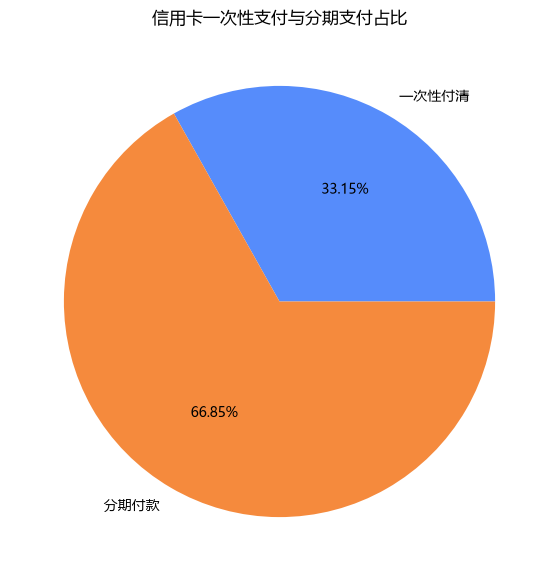

In [23]:
#绘制信用卡支付方式占比图（排除0次支付干扰）
credit_rate = pd.Series({
    "一次性付清":credit_one / credit_valid * 100,
    "分期付款":credit_installment / credit_valid * 100
})
credit_rate.plot(
    kind="pie",
    autopct = "%.2f%%",
    figsize = (7,7),
    startangle = 0#90度开始绘制
)
plt.title("信用卡一次性支付与分期支付占比")
plt.ylabel("")
plt.show()

In [ ]:
#结论：
#1.信用卡贡献了总支付金额的78.34%，是主要的支付渠道，银行票据贡献了17.92%排名第二
#2.在有效信用卡支付记录中，分期支付占66.85%，明显高于一次性支付